# caminho base para teste

In [ ]:
!apt-get install ffmpeg

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 4 not upgraded.


In [ ]:
!pip install contextily

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx
import glob
import os
from google.colab import drive


drive.mount('/content/drive')

Mounted at /content/drive


## Tentativa 1 de criar rota isolada

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx

# caminhos
gpkg_path = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/2025-11-09-07-23-58-838.gpkg"
csv_path  = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/BKP_CSVs/2025-11-09-07-23-58-838.csv"

# carregar dados
gdf = gpd.read_file(gpkg_path)
df = pd.read_csv(csv_path)

# tempo
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df = df.sort_values("datetime_utc")

# alinhar tamanhos
n = min(len(df), len(gdf))
df = df.iloc[:n]
gdf = gdf.iloc[:n]

# reduzir pontos (performance)
df = df.iloc[::5]
gdf = gdf.iloc[::5]
n = len(df)

# coordenadas (lon, lat)
coords_raw = [(geom.x, geom.y) for geom in gdf.geometry]

# linha contínua
linha = LineString(coords_raw)

# suavizar
distances = np.linspace(0, linha.length, n)
points = [linha.interpolate(d) for d in distances]

xs = [p.x for p in points]
ys = [p.y for p in points]

# transformar para CRS do mapa (metros)
gdf_plot = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(xs, ys),
    crs="EPSG:4326"
).to_crs(epsg=3857)

xs = gdf_plot.geometry.x.values
ys = gdf_plot.geometry.y.values

# plot
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_aspect('equal')

# limites
margin = 50
ax.set_xlim(xs.min() - margin, xs.max() + margin)
ax.set_ylim(ys.min() - margin, ys.max() + margin)

# mapa de fundo
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

# elementos animados
line, = ax.plot([], [], linewidth=3)
point, = ax.plot([], [], marker='o')

# função de update
def update(frame):
    if frame < 2:
        return line, point

    line.set_data(xs[:frame], ys[:frame])
    point.set_data([xs[frame-1]], [ys[frame-1]])

    return line, point

# controlar velocidade
step = 1
frames = range(0, n, step)

ani = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)

# salvar vídeo
# output_path = "/content/drive/MyDrive/rota_animada_mapa.mp4"
# writer = FFMpegWriter(fps=10)
# ani.save(output_path, writer=writer)

# print("Vídeo salvo em:", output_path)

# tentativa 1 de ampliar

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx
import glob
import os

# pasta com GPKGs
folder = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg"

files = glob.glob(folder)

rotas = []

# carregar todas rotas
for file in files:
    gdf = gpd.read_file(file)

    coords = [(geom.x, geom.y) for geom in gdf.geometry]

    if len(coords) < 2:
        continue

    linha = LineString(coords)

    n = min(len(coords), 200)  # limitar tamanho
    distances = np.linspace(0, linha.length, n)
    points = [linha.interpolate(d) for d in distances]

    xs = [p.x for p in points]
    ys = [p.y for p in points]

    rotas.append((xs, ys))

# transformar tudo pra CRS do mapa
all_points = []
for xs, ys in rotas:
    all_points.extend(list(zip(xs, ys)))

gdf_all = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        [p[0] for p in all_points],
        [p[1] for p in all_points]
    ),
    crs="EPSG:4326"
).to_crs(epsg=3857)

# separar de volta
idx = 0
rotas_proj = []

for xs, ys in rotas:
    n = len(xs)
    sub = gdf_all.iloc[idx:idx+n]
    rotas_proj.append((sub.geometry.x.values, sub.geometry.y.values))
    idx += n

# limites do mapa
all_x = np.concatenate([r[0] for r in rotas_proj])
all_y = np.concatenate([r[1] for r in rotas_proj])

fig, ax = plt.subplots(figsize=(6,6))
ax.set_aspect('equal')

margin = 50
ax.set_xlim(all_x.min()-margin, all_x.max()+margin)
ax.set_ylim(all_y.min()-margin, all_y.max()+margin)

ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
9
# criar linhas
lines = [ax.plot([], [], linewidth=2)[0] for _ in rotas_proj]

# animação
def update(frame):
    for i, (xs, ys) in enumerate(rotas_proj):
        if frame < len(xs):
            lines[i].set_data(xs[:frame], ys[:frame])
    return lines

# frames baseados na maior rota
max_len = max(len(xs) for xs, _ in rotas_proj)

ani = FuncAnimation(fig, update, frames=range(0, max_len, 2), interval=200, blit=True)


# # salvar
# output_path = "/content/drive/MyDrive/rotas_todas.mp4"
# writer = FFMpegWriter(fps=5)
# ani.save(output_path, writer=writer)

# print("Salvo em:", output_path)


# Procurando o arquivo que está fora do padrão
A ideia é basicamente passar por todos os arquivos e ver qual que tem um pulo muito grande (1km) de um frame para o outro.

In [ ]:
import geopandas as gpd
import glob

files = glob.glob("/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg")

for file in files:
    gdf = gpd.read_file(file)
    if len(gdf) < 2: continue #checa se o dado tem mais de 2 frames

    #passa para metros para medir a distância real
    gdf_metros = gdf.to_crs(epsg=3857)

    #calcula o maior pulo entre um ponto e o próximo
    pulos = gdf_metros.geometry.distance(gdf_metros.geometry.shift())
    maior_pulo = pulos.max()

    #testa se tem um pulo de mais de 1km
    if maior_pulo > 1000:
        print(f"ACHEI O CULPADO! Arquivo: {file}")
        print(f"O GPS deu um pulo de {maior_pulo:.0f} metros em uma única leitura.")

# Visualização da rota com o pulo

In [ ]:
# 1. Indique o arquivo que quer ver
caminho = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/2025-11-11-07-24-55-645.gpkg"
gdf = gpd.read_file(caminho)

# 2. CONVERSÃO OBRIGATÓRIA PARA O MAPA DE FUNDO:
# Transforma as coordenadas para o sistema Web Mercator (metros)
gdf_projetado = gdf.to_crs(epsg=3857)

# 3. Criar a figura (ajuste o figsize se quiser maior)
fig, ax = plt.subplots(figsize=(10, 10))

# 4. Plotar as rotas (ajuste cor e espessura aqui)
gdf_projetado.plot(ax=ax, color='red', linewidth=3, zorder=2)

# 5. Adicionar o mapa de ruas por baixo
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, zorder=1)

# Ocultar as bordas com números para ficar mais bonito
ax.set_axis_off()

plt.title("Visualização da Rota no Mapa", fontsize=16)
plt.show()

# Plotando os caminhos sem aquela rota

Processando arquivos e ignorando o Spike de GPS...
Sucesso! Vídeo limpo salvo em: /content/drive/MyDrive/rotas_animadas_sem_erro2.mp4


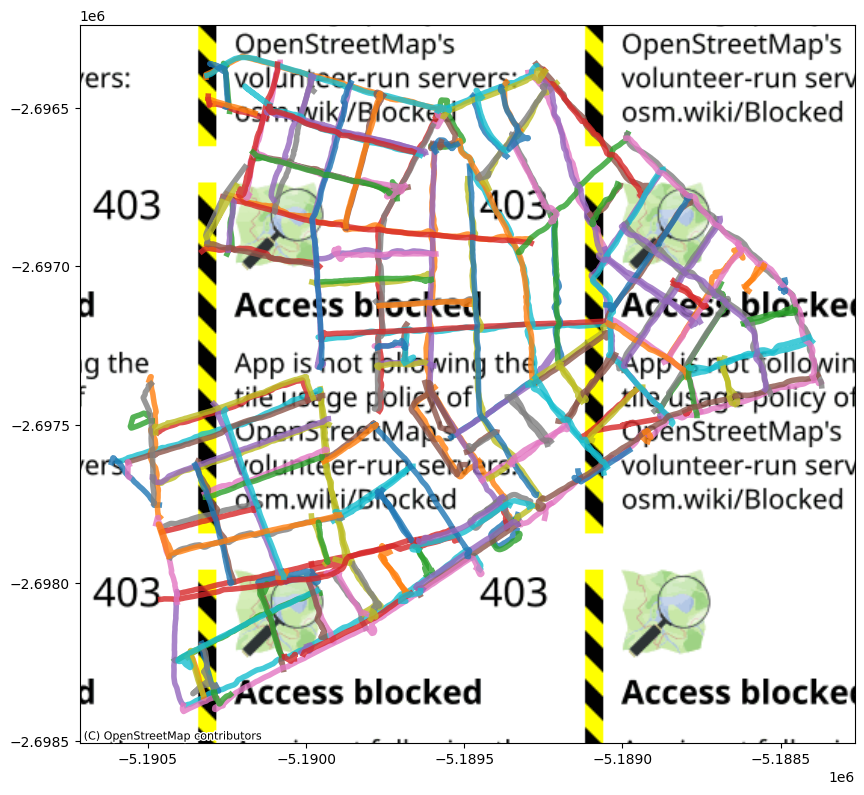

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx
import glob
import os

folder = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg"
files = glob.glob(folder)

rotas_proj = []

#esse é o arquivo com o pulo
arquivo_corrompido = "2025-11-11-07-24-55-645.gpkg"

print(f"Processando arquivos e ignorando o Spike de GPS...")

for file in files:
    nome_atual = os.path.basename(file)

    #se for o arquivo com o pulo, o código pula para o próximo
    if nome_atual == arquivo_corrompido:
        continue

    try:
        gdf = gpd.read_file(file)
        if len(gdf) < 2: continue

        #o resto é igual
        coords = [(geom.x, geom.y) for geom in gdf.geometry]

        if coords[0] == coords[-1] and len(coords) > 2:
            coords.pop()

        linha_bruta = LineString(coords)

        n_points = 200
        distances = np.linspace(0, linha_bruta.length, n_points)
        points_interp = [linha_bruta.interpolate(d) for d in distances]

        temp_gdf = gpd.GeoDataFrame(
            geometry=gpd.points_from_xy([p.x for p in points_interp], [p.y for p in points_interp]),
            crs="EPSG:4326"
        ).to_crs(epsg=3857)

        rotas_proj.append((temp_gdf.geometry.x.values, temp_gdf.geometry.y.values))

    except Exception as e:
        print(f"Erro em {nome_atual}: {e}")


if rotas_proj:
    all_x = np.concatenate([r[0] for r in rotas_proj])
    all_y = np.concatenate([r[1] for r in rotas_proj])

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_aspect('equal')

    margin = 100
    ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
    ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
    lines = [ax.plot([], [], linewidth=4, alpha=0.8)[0] for _ in rotas_proj]

    def update(frame):
        for i, (xs, ys) in enumerate(rotas_proj):
            idx = min(frame, len(xs) - 1)
            lines[i].set_data(xs[:idx], ys[:idx])
        return lines

    max_frames = max(len(r[0]) for r in rotas_proj)
    ani = FuncAnimation(fig, update, frames=range(0, max_frames, 2), interval=100, blit=True)

    output_path = "/content/drive/MyDrive/rotas_animadas_sem_erro2.mp4"
    ani.save(output_path, writer=FFMpegWriter(fps=10))
    print(f"Sucesso! Vídeo limpo salvo em: {output_path}")

# Vamos transformar o código em uma função

In [ ]:
def gerar_animacao_rotas_sem_km(
    pasta_origem,
    caminho_saida,
    tempo_video=10,
    arquivos_ignorar=None,
    fps=30,
):
  pulo_frames = 1
  n_pontos = int(tempo_video * fps)

  """
    Processa arquivos .gpkg de uma pasta, interpola as rotas e gera uma animação.
    """
  if arquivos_ignorar is None:
      arquivos_ignorar = []

  files = glob.glob(pasta_origem)
  rotas_proj = []

  print(f"Iniciando processamento. Buscando arquivos em: {pasta_origem}")

  for file in files:
      nome_atual = os.path.basename(file)

      # Se o arquivo estiver na lista de ignorados, o código pula para o próximo
      if nome_atual in arquivos_ignorar:
          print(f"Ignorando arquivo: {nome_atual}")
          continue

      try:
          gdf = gpd.read_file(file)
          if len(gdf) < 2:
              continue

          coords = [(geom.x, geom.y) for geom in gdf.geometry]

          if coords[0] == coords[-1] and len(coords) > 2:
              coords.pop()

          linha_bruta = LineString(coords)

          distances = np.linspace(0, linha_bruta.length, n_pontos)
          points_interp = [linha_bruta.interpolate(d) for d in distances]

          temp_gdf = gpd.GeoDataFrame(
              geometry=gpd.points_from_xy([p.x for p in points_interp], [p.y for p in points_interp]),
              crs="EPSG:4326"
          ).to_crs(epsg=3857)

          rotas_proj.append((temp_gdf.geometry.x.values, temp_gdf.geometry.y.values))

      except Exception as e:
          print(f"Erro em {nome_atual}: {e}")

  if not rotas_proj:
      print("Nenhuma rota válida foi encontrada para gerar a animação.")
      return

    # Preparação dos dados para o plot
  all_x = np.concatenate([r[0] for r in rotas_proj])
  all_y = np.concatenate([r[1] for r in rotas_proj])

  fig, ax = plt.subplots(figsize=(10, 10))
  ax.set_aspect('equal')

  margin = 100
  ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
  ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

  ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
  lines = [ax.plot([], [], linewidth=4, alpha=0.8)[0] for _ in rotas_proj]

  def update(frame):
      for i, (xs, ys) in enumerate(rotas_proj):
          idx = min(frame, len(xs) - 1)
          lines[i].set_data(xs[:idx], ys[:idx])
      return lines

  max_frames = max(len(r[0]) for r in rotas_proj)

  # Cria a animação aplicando o pulo de frames definido nos parâmetros
  ani = FuncAnimation(
      fig,
      update,
      frames=range(0, max_frames, pulo_frames),
      interval=100,
      blit=True
  )

  print("Renderizando vídeo. Isso pode levar alguns minutos...")
  ani.save(caminho_saida, writer=FFMpegWriter(fps=fps))
  print(f"Sucesso! Vídeo salvo em: {caminho_saida}")

  # Fecha a figura para liberar memória RAM
  plt.close(fig)

# Vamos agora adicionar a kilometragem no canto da animação

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx
import glob
import os

def gerar_animacao_rotas(
    pasta_origem,
    caminho_saida,
    tempo_video,
    arquivos_ignorar=None,
    fps=30
):
    """
    Processa arquivos .gpkg de uma pasta, interpola as rotas e gera uma animação.
    """

    n_pontos = int(tempo_video * fps)

    if arquivos_ignorar is None:
        arquivos_ignorar = []

    files = glob.glob(pasta_origem)
    rotas_proj = []

    distancia_total_metros = 0

    print(f"Iniciando processamento. Buscando arquivos em: {pasta_origem}")

    for file in files:
        nome_atual = os.path.basename(file)

        if nome_atual in arquivos_ignorar:
            print(f"Ignorando arquivo: {nome_atual}")
            continue

        try:
            gdf = gpd.read_file(file)
            if len(gdf) < 2:
                continue

            coords = [(geom.x, geom.y) for geom in gdf.geometry]

            if coords[0] == coords[-1] and len(coords) > 2:
                coords.pop()

            linha_bruta = LineString(coords)

            linha_metrica = gpd.GeoSeries([linha_bruta], crs="EPSG:4326").to_crs(epsg=3857)
            distancia_total_metros += linha_metrica.length.iloc[0]

            distances = np.linspace(0, linha_bruta.length, n_pontos)
            points_interp = [linha_bruta.interpolate(d) for d in distances]

            temp_gdf = gpd.GeoDataFrame(
                geometry=gpd.points_from_xy([p.x for p in points_interp], [p.y for p in points_interp]),
                crs="EPSG:4326"
            ).to_crs(epsg=3857)

            rotas_proj.append((temp_gdf.geometry.x.values, temp_gdf.geometry.y.values))

        except Exception as e:
            print(f"Erro em {nome_atual}: {e}")

    if not rotas_proj:
        print("Nenhuma rota válida foi encontrada para gerar a animação.")
        return

    all_x = np.concatenate([r[0] for r in rotas_proj])
    all_y = np.concatenate([r[1] for r in rotas_proj])

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_aspect('equal')

    margin = 100
    ax.set_xlim(all_x.min() - margin, all_x.max() + margin)
    ax.set_ylim(all_y.min() - margin, all_y.max() + margin)

    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
    lines = [ax.plot([], [], linewidth=4, alpha=0.8)[0] for _ in rotas_proj]

    # Cria o texto inicialmente zerado e guarda na variável
    texto_distancia = ax.text(
        0.95, 0.05,
        "Total: 0.0 km",
        transform=ax.transAxes,
        fontsize=18,
        fontweight='bold',
        color='white',
        ha='right',
        bbox=dict(facecolor='black', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.5')
    )

    def update(frame):
        # Atualiza o desenho das linhas
        for i, (xs, ys) in enumerate(rotas_proj):
            idx = min(frame, len(xs) - 1)
            lines[i].set_data(xs[:idx], ys[:idx])

        # Calcula a distância atual baseada no frame e atualiza o texto
        if n_pontos > 1:
            dist_atual_metros = distancia_total_metros * (frame / (n_pontos - 1))
        else:
            dist_atual_metros = distancia_total_metros

        dist_atual_km = dist_atual_metros / 1000
        texto_distancia.set_text(f"Total: {dist_atual_km:.1f} km")

        # Retorna as linhas E o texto para a animação atualizar ambos na tela
        return lines + [texto_distancia]

    ani = FuncAnimation(
        fig,
        update,
        frames=n_pontos,
        interval=100,
        blit=True
    )

    print("Renderizando vídeo. Isso pode levar alguns minutos...")
    ani.save(caminho_saida, writer=FFMpegWriter(fps=fps))
    print(f"Sucesso! Vídeo salvo em: {caminho_saida}")

    plt.close(fig)


# Chamada da função "gerar_animação_rotas"

Parâmetros obrigatórios:

1- Pasta da qual estão disponíveis os dados

2- Caminho que vai sair o vídeo

Parâmetros opcionais:

3- Tempo de vídeo em segundos (padrão = 10s)

4- Arquivos a serem ignorados

5- Fps (padrão = 30)


# Exemplo:
esse é o exemplo que plotamos anteriormente:

gerar_animação_rotas(

  "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg",

  "/content/drive/MyDrive/rotas_animadas_sem_erro2.mp4",

  10,

  "2025-11-11-07-24-55-645.gpkg",

  10 )



# Teste da função

In [ ]:
gerar_animacao_rotas(

"/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg",

"/content/drive/MyDrive/rotas_com_km3.mp4",

10,

"2025-11-11-07-24-55-645.gpkg")